In [4]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA  = Path.home() / "Documents" / "10084619"
WAVES = DATA / "submetered_new"
FS  = 30_000        # samples per second
SPC = FS // 60      # samples per mains cycle = 500

print(len(list(WAVES.glob("*.csv"))))   # should print 1876

meta_raw = json.load(open(DATA / "metadata_submetered.json"))
meta = pd.DataFrame([
    {"id": int(k), "type": r["appliance"]["type"], "location": r["location"]}
    for k, r in meta_raw.items()
])
meta = meta.set_index("id")

def load_wave(rec_id):
    df = pd.read_csv(WAVES / f"{rec_id}.csv", header=None, names=["current", "voltage"]) #add csv to dataframe
    df["time_s"] = np.arange(len(df)) / FS #store time in seconds in dataframe
    return df

1876


In [18]:
with open(DATA / "metadata_submetered.json") as f:
    meta_raw = json.load(f)

# one full record, so you can see how it's nested
print(json.dumps(meta_raw[next(iter(meta_raw))], indent=2))

# every field across all records, flattened into columns
raw = pd.json_normalize(list(meta_raw.values()))
print(raw.columns.tolist())
raw.head()


{
  "appliance": {
    "brand": "",
    "current": "",
    "load": "NL",
    "manufacture_year": "",
    "model_number": "",
    "notes": "",
    "status": "off-on",
    "type": "Compact Fluorescent Lamp",
    "voltage": "",
    "wattage": ""
  },
  "header": {
    "collection_time": "July, 2013",
    "notes": "some instances are not well calibrated, meta data are not complete",
    "sampling_frequency": "30000Hz"
  },
  "instances": {
    "length": "2.00s"
  },
  "location": "house1"
}
['location', 'appliance.brand', 'appliance.current', 'appliance.load', 'appliance.manufacture_year', 'appliance.model_number', 'appliance.notes', 'appliance.status', 'appliance.type', 'appliance.voltage', 'appliance.wattage', 'header.collection_time', 'header.notes', 'header.sampling_frequency', 'instances.length', 'appliance.appliance_notes']


,location,appliance.brand,appliance.current,appliance.load,appliance.manufacture_year,appliance.model_number,appliance.notes,appliance.status,appliance.type,appliance.voltage,appliance.wattage,header.collection_time,header.notes,header.sampling_frequency,instances.length,appliance.appliance_notes
0,house1,,,NL,,,,off-on,Compact Fluorescent Lamp,,,"July, 2013","some instances are not well calibrated, meta d...",30000Hz,2.00s,NaN
1,house1,,,NL,,,,off-on,Compact Fluorescent Lamp,,,"July, 2013","some instances are not well calibrated, meta d...",30000Hz,2.00s,NaN
2,house1,,,NL,,,,off-on,Compact Fluorescent Lamp,,,"July, 2013","some instances are not well calibrated, meta d...",30000Hz,2.00s,NaN
3,house1,,,NL,,,,off-on,Compact Fluorescent Lamp,,,"July, 2013","some instances are not well calibrated, meta d...",30000Hz,2.00s,NaN
4,house1,,,NL,,,,off-on,Compact Fluorescent Lamp,,,"July, 2013","some instances are not well calibrated, meta d...",30000Hz,2.00s,NaN


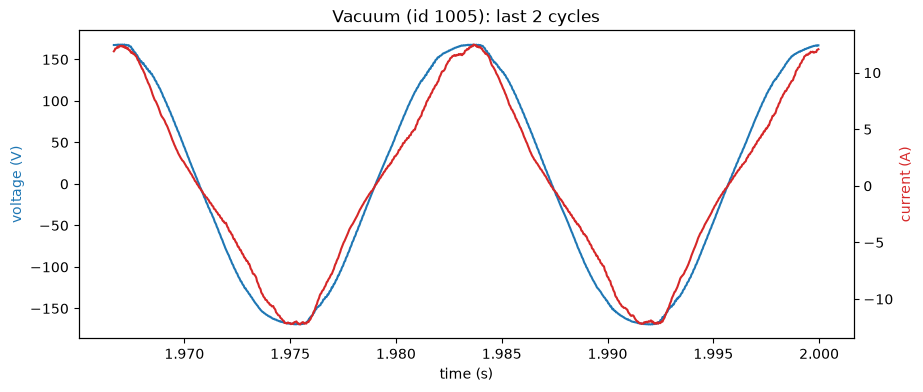

In [14]:
rec_id = 1005
w = load_wave(rec_id)
part = w.iloc[-2 * SPC:]                      # last 2 cycles = steady state

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(part["time_s"], part["voltage"], color="tab:blue")
ax1.set_xlabel("time (s)")
ax1.set_ylabel("voltage (V)", color="tab:blue")

ax2 = ax1.twinx()                             # second y-axis, because amps are much smaller than volts
ax2.plot(part["time_s"], part["current"], color="tab:red")
ax2.set_ylabel("current (A)", color="tab:red")

plt.title(f"{meta.loc[rec_id, 'type']} (id {rec_id}): last 2 cycles")
plt.show()

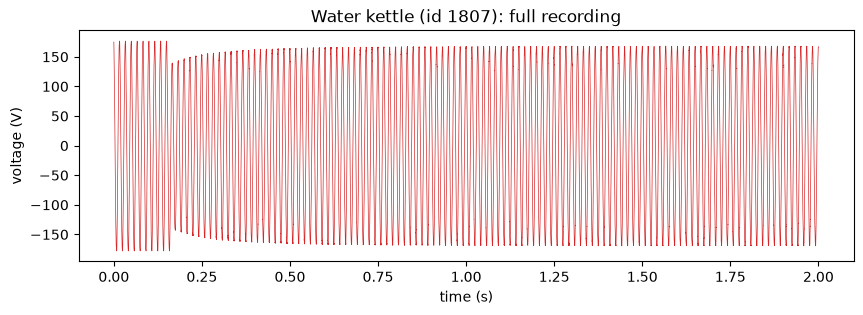

In [12]:
plt.figure(figsize=(10, 3))
plt.plot(w["time_s"], w["voltage"], linewidth=0.5, color="tab:red")
plt.xlabel("time (s)"); plt.ylabel("voltage (V)")
plt.title(f"{meta.loc[rec_id, 'type']} (id {rec_id}): full recording")
plt.show()

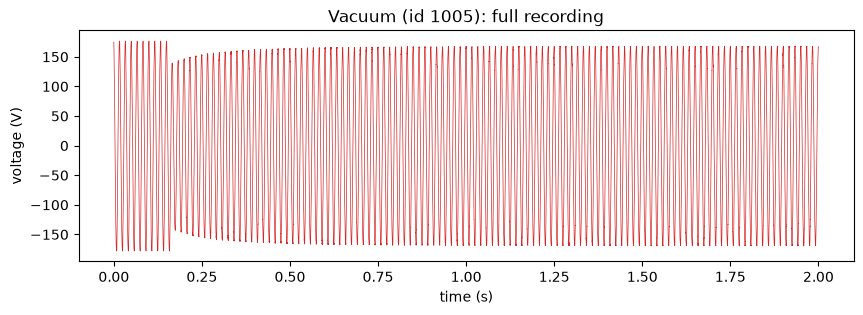

In [ ]:
plt.figure(figsize=(10, 3))
plt.plot(w["time_s"], w["voltage"], linewidth=0.5, color="tab:red")
plt.xlabel("time (s)"); plt.ylabel("voltage (V)")
plt.title(f"{meta.loc[rec_id, 'type']} (id {rec_id}): full recording")
plt.show()

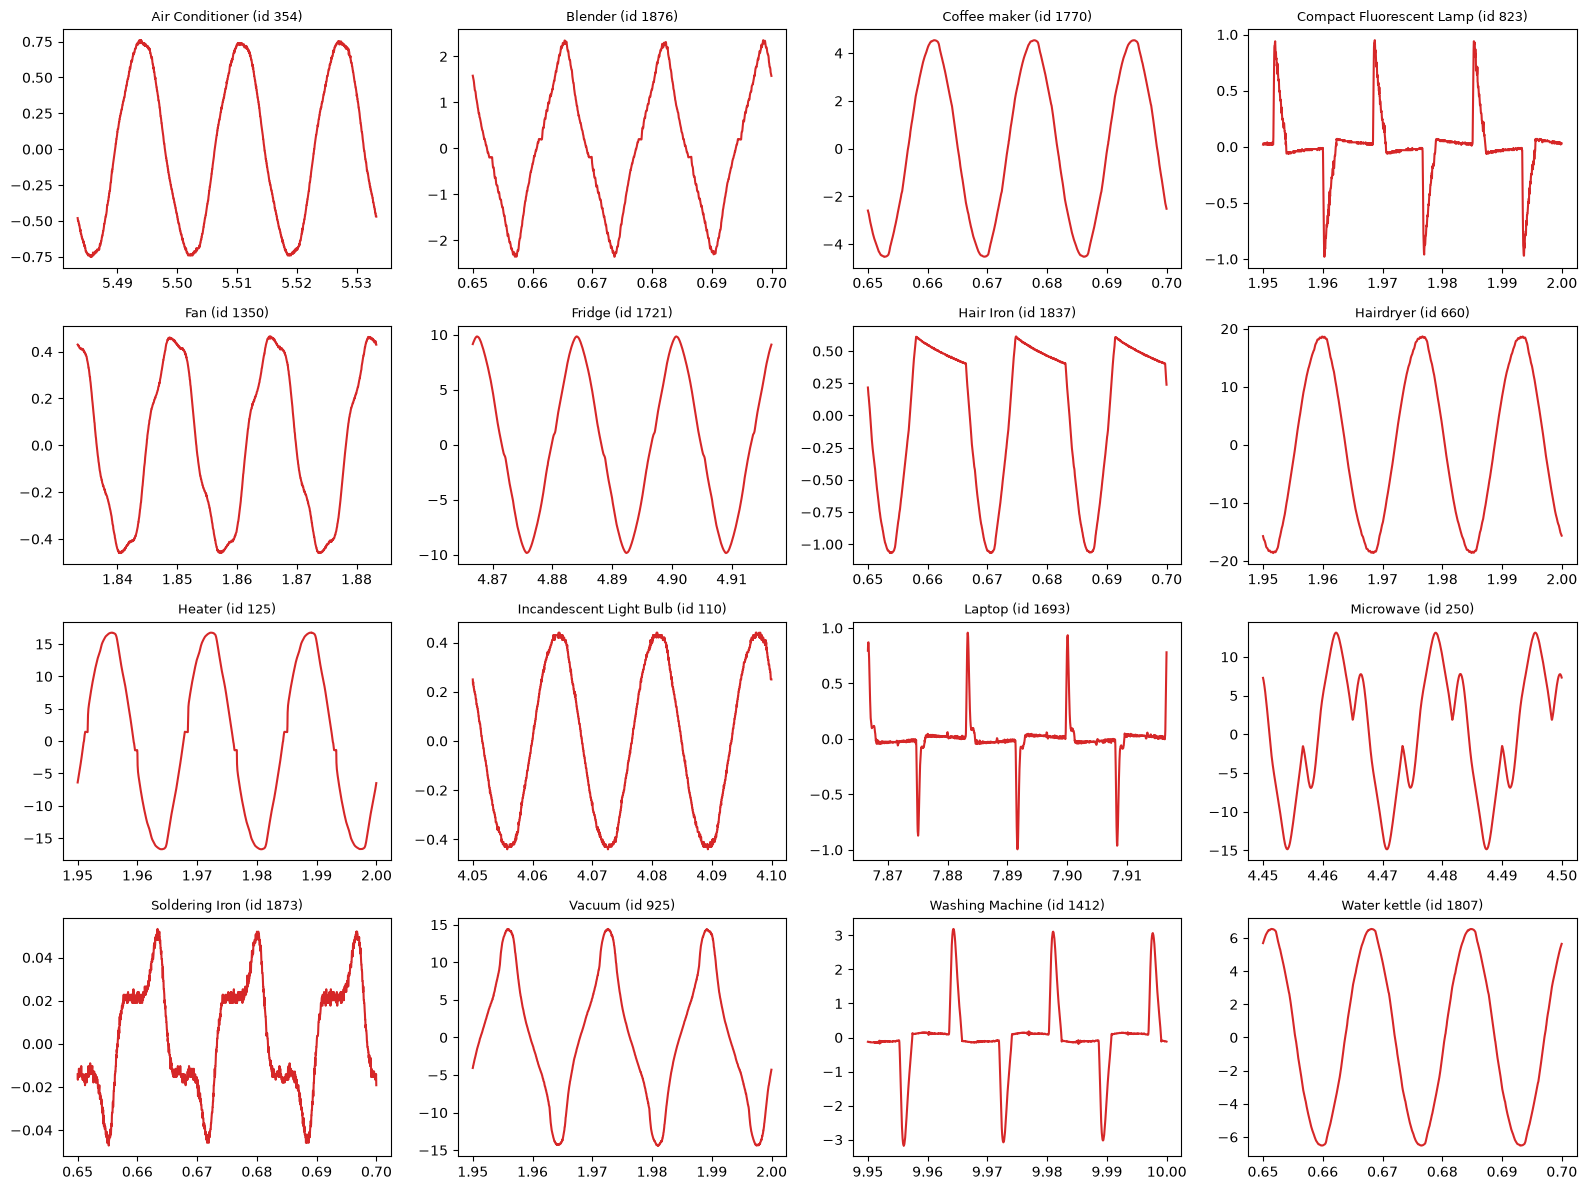

In [7]:
types = sorted(meta["type"].unique())          # 16 types → a 4×4 grid
fig, axes = plt.subplots(4, 4, figsize=(16, 12))

for ax, t in zip(axes.flat, types):
    rec_id = meta.index[meta["type"] == t].to_series().sample(1, random_state=0).iloc[0]
    part = load_wave(rec_id).iloc[-3 * SPC:]   # last 3 cycles
    ax.plot(part["time_s"], part["current"], color="tab:red")
    ax.set_title(f"{t} (id {rec_id})", fontsize=9)

plt.tight_layout()
plt.show()

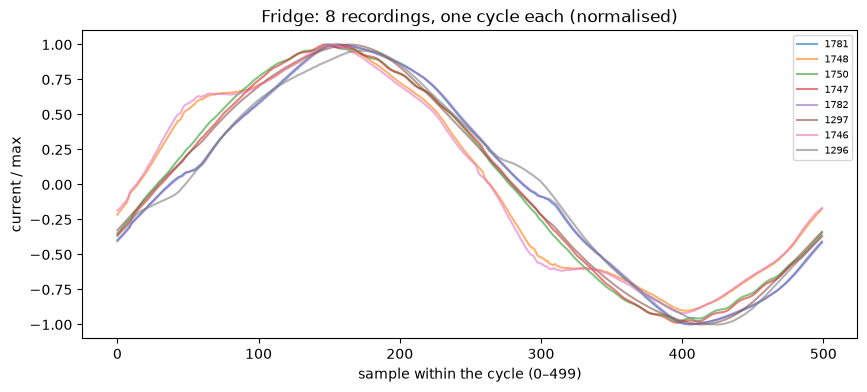

In [8]:
def last_cycle(w):
    v = w["voltage"].to_numpy()
    i = w["current"].to_numpy()
    rising = np.flatnonzero((v[:-1] < 0) & (v[1:] >= 0))   # voltage crosses 0 going up
    start = rising[rising <= len(v) - SPC][-1]             # last one with a full cycle after it
    return i[start:start + SPC], v[start:start + SPC]

t = "Fridge"
ids = meta.index[meta["type"] == t].to_series().sample(8, random_state=1)

plt.figure(figsize=(10, 4))
for rec_id in ids:
    i, v = last_cycle(load_wave(rec_id))
    plt.plot(i / np.abs(i).max(), alpha=0.6, label=str(rec_id))   # scale to ±1 to compare shape
plt.title(f"{t}: 8 recordings, one cycle each (normalised)")
plt.xlabel("sample within the cycle (0–499)"); plt.ylabel("current / max")
plt.legend(fontsize=7)
plt.show()

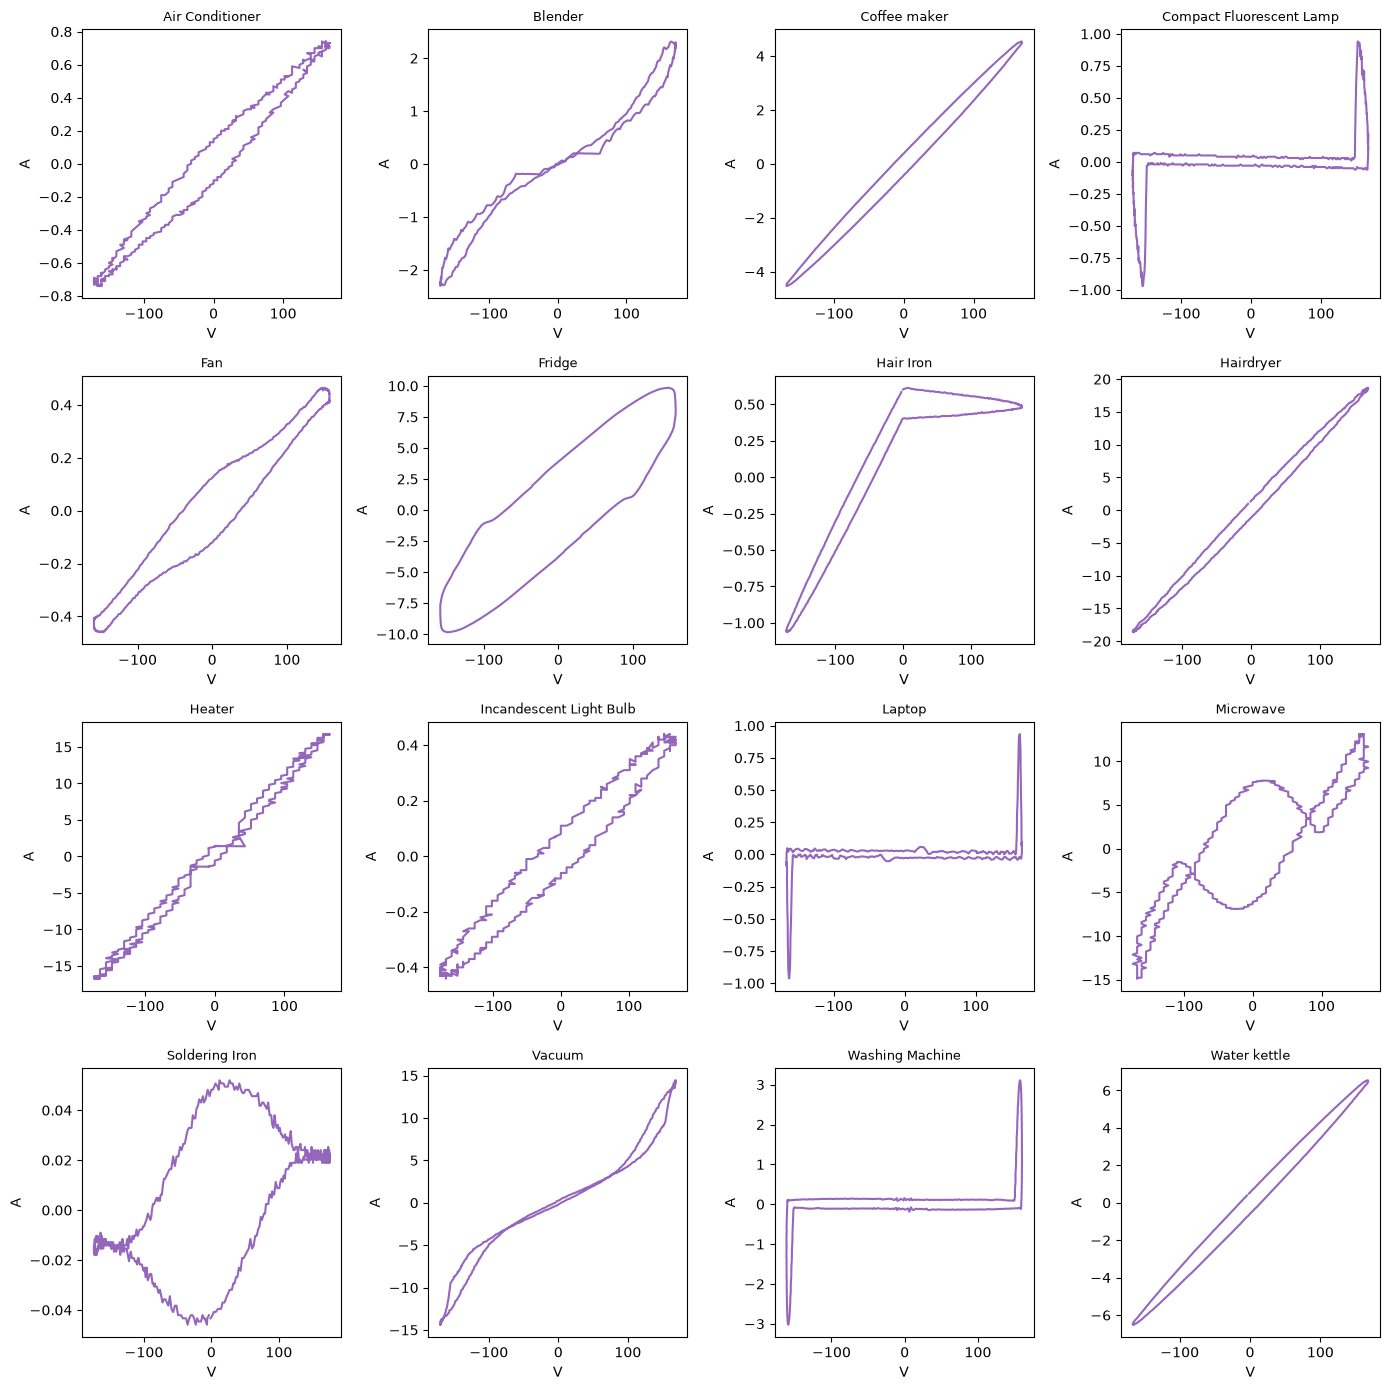

In [9]:
fig, axes = plt.subplots(4, 4, figsize=(14, 14))
for ax, t in zip(axes.flat, types):
    rec_id = meta.index[meta["type"] == t].to_series().sample(1, random_state=0).iloc[0]
    i, v = last_cycle(load_wave(rec_id))
    ax.plot(v, i, color="tab:purple")
    ax.set_title(t, fontsize=9)
    ax.set_xlabel("V"); ax.set_ylabel("A")
plt.tight_layout()
plt.show()